<a href="https://colab.research.google.com/github/swaran3564/Ml_116/blob/main/set_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv('/content/train_1.csv')

features = ['GrLivArea', 'BedroomAbvGr', 'FullBath',
            'GarageCars', 'GarageArea', 'OverallQual',
            'YearBuilt', 'LotArea', 'Neighborhood']

X = df[features]
y = df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


Simple R2: 0.5542632452871117
Multiple R2: 0.7853323020176416


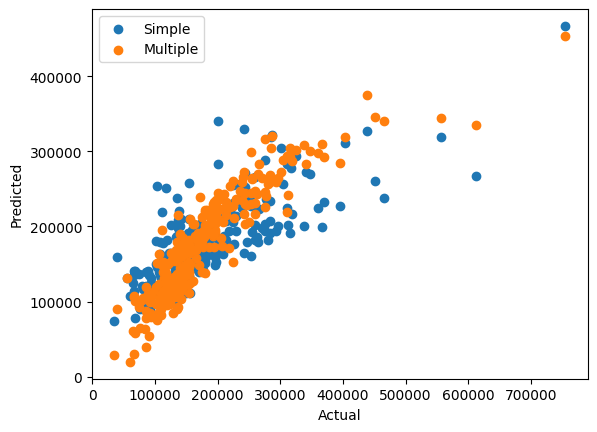

In [2]:

# Simple Linear
m1 = make_pipeline(SimpleImputer(), StandardScaler(), LinearRegression())
m1.fit(X_train[['GrLivArea']], y_train)
p1 = m1.predict(X_test[['GrLivArea']])

# Multiple Linear
m2 = make_pipeline(SimpleImputer(), StandardScaler(), LinearRegression())
m2.fit(X_train.drop(columns='Neighborhood'), y_train)
p2 = m2.predict(X_test.drop(columns='Neighborhood'))

print("Simple R2:", r2_score(y_test, p1))
print("Multiple R2:", r2_score(y_test, p2))

# Graph
plt.scatter(y_test, p1, label='Simple')
plt.scatter(y_test, p2, label='Multiple')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.legend()
plt.show()


   Model      R2        RMSE
0  Ridge  0.8225  36900.0831
1  LASSO  0.8226  36891.4656


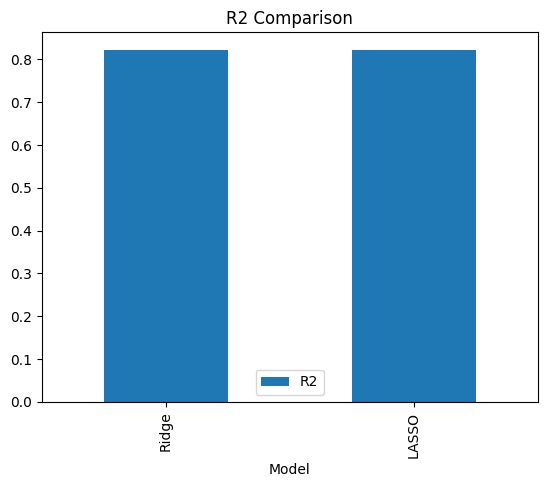

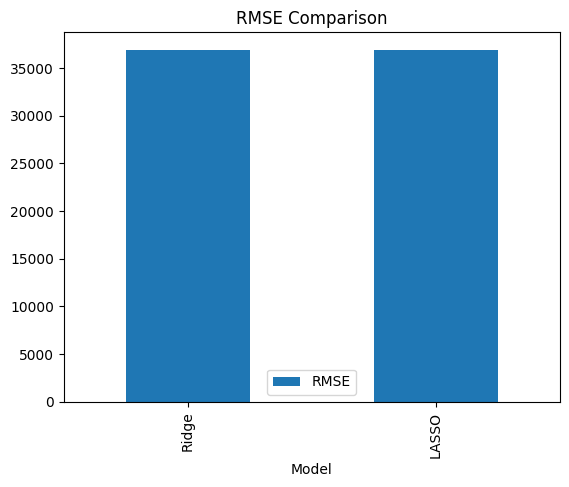

In [3]:

# Preprocessing
num = X.select_dtypes(include=np.number).columns
cat = X.select_dtypes(include='object').columns

pre = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(), StandardScaler()), num),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore')), cat)
])

# Models and Evaluation
results = []

for name, model in {
    'Ridge': Ridge(alpha=1.0),
    'LASSO': Lasso(alpha=0.5, max_iter=10000)
}.items():

    pipe = make_pipeline(pre, model)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)

    results.append([name, r2_score(y_test, p),
                    np.sqrt(mean_squared_error(y_test, p))])

# Comparison
r = pd.DataFrame(results, columns=['Model', 'R2', 'RMSE'])
print(r.round(4))

# Graphs
r.plot(x='Model', y=['R2'], kind='bar', title='R2 Comparison')
plt.show()

r.plot(x='Model', y=['RMSE'], kind='bar', title='RMSE Comparison')
plt.show()
